In [1]:
import sys

print(sys.version)

3.14.10 (main, Nov 11 2026, 00:18:44) [Clang 23.1.3 ]


# Common Boggle Words

What words appear most often in a game of Boggle?

[Naively](https://english.stackexchange.com/questions/12747/is-it-spelt-na%C3%AFve-or-naive), we can count $16! \cdot 6^{16} \approx 5.9 \cdot 10^{25}$ different boards, not taking duplicate letters into account. This many boards is too a numerous; even if discovering words per board was as fast as $\mathcal{O}(\mathtt{pass})$, it would be too much.

In [2]:
import time

import numpy as np


def simple_loop(n):
    """Return how many seconds a simple loop takes."""
    start = time.time()
    for _ in range(n):
        pass
    return time.time() - start


x = np.arange(1, 1_000_000, 10_000)
y = [simple_loop(int(n)) for n in x]

a, b = np.polyfit(x, y, deg=1)  # seconds per loop step, and fixed overhead
seconds = a * 5.9e25 + b       # one empty loop step per board
print(f"about {seconds / (365.25 * 24 * 3600):.1g} years")

about 1e+10 years


Great Scott!

In [3]:
from math import log10

C_MAX_INT = 2**31
log10(C_MAX_INT/365)

6.769637001126942

So we will recourse to sampling!

The game Boggle has a square board, with 16 slots for cubes. Each cube has letters on its 6 faces. Starting each game, the board is shuffled so that each cube is in a random slot, _and_ each cube has a random face showing.

Players compete to find most words showing on the resultant board. A player's score is based on the number of words that no other players found. Where longer words that no other players found are scored higher.

Words can be constructed from any non-repeating contiguous sequence of horizontal, vertical, or diagonal cubes. But sequences can't wrap around the board. Note too that the same letter may appear twice in a path, but not the same cube.


Lastly, the words must belong to an agreed upon dictionary, and be at least some minimum length.

## Simulating Boggle

There are 16 cubes one will find in a standard Boggle board:

In [4]:
from boggle import CUBES

CUBES

[('a', 'a', 'e', 'e', 'g', 'n'),
 ('a', 'b', 'b', 'j', 'o', 'o'),
 ('a', 'c', 'h', 'o', 'p', 's'),
 ('a', 'f', 'f', 'k', 'p', 's'),
 ('a', 'o', 'o', 't', 't', 'w'),
 ('c', 'i', 'm', 'o', 't', 'u'),
 ('d', 'e', 'i', 'l', 'r', 'x'),
 ('d', 'e', 'l', 'r', 'v', 'y'),
 ('d', 'i', 's', 't', 't', 'y'),
 ('e', 'e', 'g', 'h', 'n', 'w'),
 ('e', 'e', 'i', 'n', 's', 'u'),
 ('e', 'h', 'r', 't', 'v', 'w'),
 ('e', 'i', 'o', 's', 's', 't'),
 ('e', 'l', 'r', 't', 't', 'y'),
 ('h', 'i', 'm', 'n', 'qu', 'u'),
 ('h', 'l', 'n', 'n', 'r', 'z')]

To simulate shaking the board, we put the cubes in a random order and show a random face of each. Every random choice takes a seeded `random.Random`, so the numbers below can be reproduced.

The code for boards and word search lives in `boggle.py`, next to this notebook, so the tests can import it too.

In [5]:
import random

from boggle import rand_board

In [6]:
rand_board(random.Random(0))

[['i', 'h', 'r', 'e'],
 ['t', 'y', 'v', 'l'],
 ['r', 'a', 's', 'e'],
 ['o', 'm', 'n', 's']]

To find viable words on a board, we'll recursively traverse paths across the showing letters. Once a sequence goes out of bounds or repeats a cube, traversal in that direction will stop. 

Now, at each step in this process we could look up the sequence in a hash table. But, it may be the case that the current sequence is not a prefix of any word in the dictionary. So, it will be more efficient to store the dictionary in a trie. [Here](http://stackoverflow.com/a/11016430) is an inspiring elegant implementation.

In [7]:
from boggle import make_trie

In [8]:
import json

t = make_trie(['apply', 'apple', 'apt'])
print(json.dumps(t, indent=2))

{
  "a": {
    "p": {
      "p": {
        "l": {
          "y": {
            "null": null
          },
          "e": {
            "null": null
          }
        }
      },
      "t": {
        "null": null
      }
    }
  }
}


Now let's write that recursive function that generates unique words on a given board, of at least some length.

In [9]:
from boggle import get_words

Finding words necessitates a dictionary, and a _Scrabble_-esque dictionary seems fitting. Conveniently, the _Words With Friends_ game's dictionary is [publicly available](http://gaming.stackexchange.com/a/7163): the Enhanced North American Benchmark Lexicon.

In [10]:
with open('enable1.txt') as f:
    trie = make_trie(word.strip() for word in f)

## Estimating Word Probabilities

To estimate word frequencies, we'll gather relative frequencies from random boards. But how many boards to sample from?

We can view the appearance of a specific word as a Bernoulli random variable with some unknown probability. We'd like to sample enough boards so that the resulting $k$ most common words are in fact the most common, and in order.

In the land of probability bounds, where Markov and Chebyshev wander wide, one called Hoeffding's inequality is particularly powerful when it comes to Bernoulli variables. It can tell us how tight an $\epsilon$-sized confidence interval should be with $n$ samples.

Specifically, let $X_1, \ldots, X_n \sim \mathrm{Bernoulli}(p)$. Then, for any $\epsilon > 0$,

$$P(\left| \overline{X_n} - p \right| > \epsilon) \le 2 e^{-2n\epsilon^2}$$

So, to be $\alpha$ confident that some variable is within error $\epsilon$ of its true value, we'll need

$$n \ge \frac{1}{2\epsilon^2}\log{\frac{2}{\alpha}}$$

samples.

This applies to any Bernoulli variable, and each random Boggle board gives a Bernoulli value to every word (it appears or it doesn't). So, we can just sample a bunch of boards, which will probably produce a tight enough bound.

However, we'll have to be very diligent about choosing our confidence $\alpha$, and tightness $\epsilon$. We can't guarantee that the top $k$ words are in fact the top $k$, and in order, but it does ossify those top probabilities with a diligently chosen $\epsilon$.

Experimenting with 1000 boards showed that top 10 words' probabilities overlap, suggesting that we need $\epsilon < 0.001$ to be, say, $\alpha = 0.1$ confident that the ordering is correct. Unfortunately, this would lead to $n \ge 1.5 \times 10^6$ boards, which is too many hours of computation. Instead we'll shoot for just having the same set of top words, rather than correct ranking. The difference in probability between the empirical most common word and the 20th (we choose $k$ arbitrarily) was about 0.01, yielding $n \ge 14979$ boards, which is more manageable.

In [11]:
%%time
from tabulate import tabulate

from boggle import count_words

NBOARDS = 14979

counts = count_words(NBOARDS, trie, min_len=4)  # board i is drawn with random.Random(i)

table = [(i, word, count/NBOARDS) for i, (word, count)
         in enumerate(counts.most_common(20), start=1)]
print(tabulate(table, headers=['Rank', 'Word', 'Frequency'], floatfmt='.4f'))

  Rank  Word      Frequency
------  ------  -----------
     1  tees         0.0662
     2  teen         0.0654
     3  tent         0.0619
     4  tone         0.0590
     5  note         0.0589
     6  teat         0.0582
     7  test         0.0563
     8  toes         0.0557
     9  rete         0.0544
    10  toea         0.0540
    11  nets         0.0539
    12  sent         0.0536
    13  nest         0.0532
    14  tets         0.0532
    15  stet         0.0532
    16  nett         0.0525
    17  neat         0.0522
    18  etna         0.0520
    19  ante         0.0520
    20  seta         0.0515
CPU times: user 462 ms, sys: 47 ms, total: 509 ms
Wall time: 14 s


For comparison, Dan Vanderkam's [sample of 50,000 boards](https://www.danvk.org/wp/2007-02-11/some-boggle-statistics/index.html) (2007) puts the most common four-letter words at teen 6.7%, tees 6.6%, tent 6.0%, note 6.0% and tone 5.8%. Those are the same words as above, within the one percentage point that Hoeffding's bound allows at this sample size.

## Common and Ordinary Word Ranking

The most common list is interesting, but some of the words are so ordinary that other players will probably know them and also find them. To improve one's chances of winning Boggle, it would be nice to have a ranking that takes into account both a word's probability of occurence, *and ordinariness*.

This is reminiscent [tf-idf weighting](http://nlp.stanford.edu/IR-book/html/htmledition/tf-idf-weighting-1.html)! Our current list gives us the *term frequency*, so all that remains is to find each term's *inverse document frequency*. Here, we assume that usage corresponds to how likely it is for a word to be known.

We'll use word usage counts from [American National Corpus](http://www.anc.org/data/anc-second-release/frequency-data/). However, some of the words from Boggle might have various endings (e.g. "apple", "apples"), and those should add in frequency for "ordinariness." So we'll stem the words for lookup.

In [12]:
from collections import defaultdict

from nltk.stem import SnowballStemmer

snow = SnowballStemmer('english')
freqs = defaultdict(float)

with open('ANC-token-count.txt', encoding='ISO-8859-1') as f:    # there's weird characters
    for word, *_, freq in map(str.split, f):
        if word == 'Total':    # there was a total count of words at the end
            continue
        freqs[snow.stem(word)] += float(freq)

min_freq = min(freqs.values())    # used for Boggle words that are not in the corpus

Now, we just need to calculate the scores of the words output a new sorted list.

In [13]:
from math import log

tfs, idfs = [], []
for word, count in counts.items():
    word = snow.stem(word)
    tfs.append(1 + count)
    idfs.append(log(1 + 1/freqs.get(word, min_freq)))

scores = sorted([(tf*idf, word) for tf, idf, word in zip(tfs, idfs, counts.keys(), strict=True)], reverse=True)
table = [(i, word, score) for i, (score, word) in enumerate(scores[:20], start=1)]
print(tabulate(table, headers=['Rank', 'Word', 'Score']))

  Rank  Word      Score
------  ------  -------
     1  toea    13700.4
     2  stet    13497.4
     3  nett    13311.3
     4  seta    13074.5
     5  rete    12905.4
     6  teat    12847.8
     7  tret    12161.2
     8  tees    12041.7
     9  etna    11937.6
    10  teth    11889.9
    11  teel    11704.5
    12  sett    11704.5
    13  haet    11704.5
    14  hest    11214
    15  hent    11146.3
    16  eath    11146.3
    17  sene    11030.2
    18  tine    10988.7
    19  leet    10944.3
    20  nite    10903.4


# Epilogue

After completing this task, several sub-topics came to mind. We address some of those here. Unlike in previous sections, we will be lax proving the correct number of boards.

## Number of Possible Words Distribution

It would be interesting to see the minimum, maximum, mean, etc. of the number of words found over all boards. For the sake of brevity, rather than fitting the distribution and devising estimators, we'll just plot a simple histogram. And I choose an arbitrarily large number of boards to sample from.

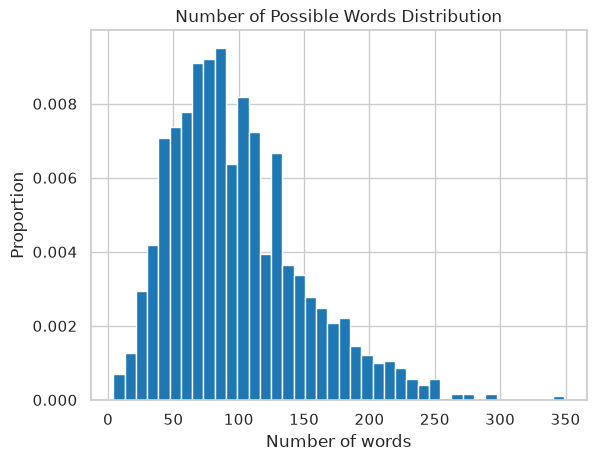

In [14]:
import matplotlib.pyplot as plt
import seaborn

%matplotlib inline
seaborn.set_context('notebook')
seaborn.set_style('whitegrid')

rng = random.Random(1)
num_words = []
for _ in range(2000):
    num_words.append(len(list(get_words(rand_board(rng), trie))))

plt.hist(num_words, bins=40, density=True)
plt.title('Number of Possible Words Distribution')
plt.xlabel('Number of words')
plt.ylabel('Proportion')
plt.show()

## Best Proportion of Vowels

A friend gave the comment that the "best" Boggle boards are comprised of 40% vowels. Best, here, was intended to mean highest number of word solutions. Now to experimentally prove this claim.

In [15]:
from collections import defaultdict
from itertools import chain

NBOARDS = 1000
data = defaultdict(int)    # store how many words found per vowel, summed over boards
vowels = set('aeiou')    # for simplicity we assume that these are the only vowels

for _ in range(NBOARDS):
    num_vowels = 0
    board = rand_board()
    for letter in chain(*board):
        if letter in vowels:
            num_vowels += 1
    num_words = len(list(get_words(board, trie, min_len=4)))
    data[num_vowels] += num_words

Now to plot the mean number of found words per number of vowels:

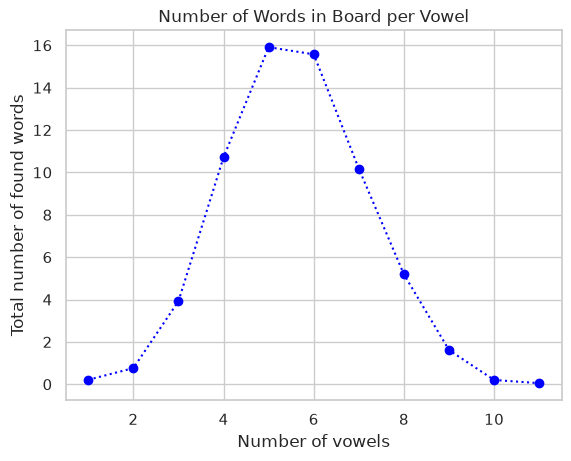

In [16]:
x, y = zip(*sorted(data.items()), strict=True)

plt.plot(x, [t/NBOARDS for t in y], 'bo:')
plt.title(r'Number of Words in Board per Vowel')
plt.xlabel('Number of vowels')
plt.ylabel('Total number of found words')
plt.show()

In [17]:
6/16

0.375

Would you look at that, 40% was pretty spot on for an off the cuff comment.

## Super Big Boggle

In [18]:
big_cubes = [
    ('s', 's', 's', 'u', 'n', 'e'),
    ('qu', 'j', 'k', 'z', 'w', 'x'),
    ('a', 'a', 'a', 's', 'f', 'r'),
    ('h', 'o', 'r', 'd', 'l', 'n'),
    ('g', 'o', 'r', 'w', 'r', 'v'),
    ('f', 's', 'i', 'r', 'a', 'a'),
    ('an', 'in', 'er', 'he', 'th', 'qu'),
    ('a', 'e', 'a', 'e', 'e', 'e'),
    ('l', 'i', 'e', 'a', 'n', 'm'),
    ('g', 'f', 'n', 'u', 'y', 'c'),
    ('a', 'e', 'm', 'e', 'e', 'e'),
    ('h', 'd', 't', 'n', 'o', 'd'),
    ('h', 's', 'e', 'r', 'i', 'l'),
    ('n', 'u', 'e', 'o', 'i', 'a'),
    ('o', 'n', 'd', 'w', 'h', 'h'),
    ('a', 'o', 'i', 'e', 'b', 'd'),
    ('l', 'h', 'h', 'r', 'd', 'o'),
    ('g', 'n', 'a', 'm', 'n', 'e'),
    ('s', 't', 'r', 'h', 'p', 'o'),
    ('n', 'd', 'e', 'a', 'n', 'n'),
    ('o', 'o', 'a', 'e', 'a', 'e'),
    ('t', 'm', 't', 'e', 'o', 't'),
    ('t', 'i', 's', 'r', 'v', 'h'),
    ('a', 'e', 'm', 'g', 'u', 'e'),
    ('t', 'i', 'l', 's', 'p', 'e'),
    ('n', 'o', 'w', 'o', 'u', 't'),
    ('y', 'r', 'y', 's', 'i', 'p'),
    ('e', 's', 'p', 't', 'i', 'c'),
    ('c', 't', 'n', 's', 'e', 'c'),
    ('y', 'r', 'f', 's', 'i', 'a'),
    ('l', 'c', 'd', 'd', 'n', 'n'),
    ('t', 'i', 't', 'c', 't', 'e', 'i'),
    ('e', 't', 'i', 'l', 'i', 's'),
    ('j', 'b', 'b', 'z', 'x', 'k'),
    ('o', 'o', 'o', 't', 'u', 't'),
    ('o', 'i', None, None, 'e', None)
]